In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier


TRAIN_ROOT = Path('../data/dataset/D01_megadataset')
TEST_ROOT = 0

LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"
LABEL_MAP = {letter: index for index, letter in enumerate(LETTERS)}

HAND_MODEL = Path("../models/hand_landmarker.task")
HAND_MODEL.parent.mkdir(parents=True, exist_ok=True)

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not HAND_MODEL.exists():
    urlretrieve(MODEL_URL, HAND_MODEL)

print("MediaPipe model:", HAND_MODEL)

MediaPipe model: ../models/hand_landmarker.task


In [2]:
def find_images(root):
    root = Path(root)

    if not root.is_dir():
        raise FileNotFoundError(root)

    paths, labels = [], []

    for path in sorted(root.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        letter = path.parent.name.upper()

        if letter in LABEL_MAP:
            paths.append(path)
            labels.append(LABEL_MAP[letter])

    if not paths:
        raise ValueError(f"No images in supported letter folders: {root}")

    return paths, np.array(labels, dtype=np.int64)

In [3]:
def read_rgb(path):
    with Image.open(path) as original:
        oriented = ImageOps.exif_transpose(original).convert("RGBA")
        background = Image.new(
            "RGBA", oriented.size, (255, 255, 255, 255)
        )
        image = Image.alpha_composite(
            background, oriented
        ).convert("RGB")

        # Limit large images while preserving aspect ratio.
        image.thumbnail((1024, 1024), Image.Resampling.LANCZOS)

        return np.array(image)

In [4]:
def create_landmarker():
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(HAND_MODEL)
        ),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
    )

    return mp.tasks.vision.HandLandmarker.create_from_options(options)

In [5]:
def get_features(rgb, landmarker):
    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb),
    )

    result = landmarker.detect(image)

    if not result.hand_landmarks:
        return None, None

    points = np.array(
        [[point.x, point.y, point.z]
         for point in result.hand_landmarks[0]],
        dtype=np.float32,
    )

    # Express coordinates in consistent units.
    height, width = rgb.shape[:2]
    points *= np.array([width, height, width], dtype=np.float32)

    # Wrist becomes the origin.
    relative = points - points[0]

    # Normalize by wrist-to-middle-finger-knuckle distance.
    scale = np.linalg.norm(relative[9])

    if scale < 1e-6:
        return None, None

    features = (relative / scale).reshape(-1)

    # 21 points × 3 coordinates = 63 features.
    return features, result.hand_landmarks[0]

In [6]:
def extract_features(paths):
    # NaN rows preserve failures in their original positions.
    features = np.full((len(paths), 63), np.nan, dtype=np.float32)
    failures = []

    with create_landmarker() as landmarker:
        for index, path in enumerate(tqdm(paths)):
            try:
                rgb = read_rgb(path)
                vector, _ = get_features(rgb, landmarker)

                if vector is None:
                    failures.append((str(path), "No usable hand landmarks"))
                else:
                    features[index] = vector

            except (OSError, ValueError, RuntimeError) as error:
                failures.append((str(path), str(error)))

    return features, failures

I0000 00:00:1792492022.686325  185599 init-domain.cc:134] Fiber init: default domain = pthread, concurrency = 15, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792492022.696794  185605 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792492022.699448  185606 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792492022.712475  185615 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


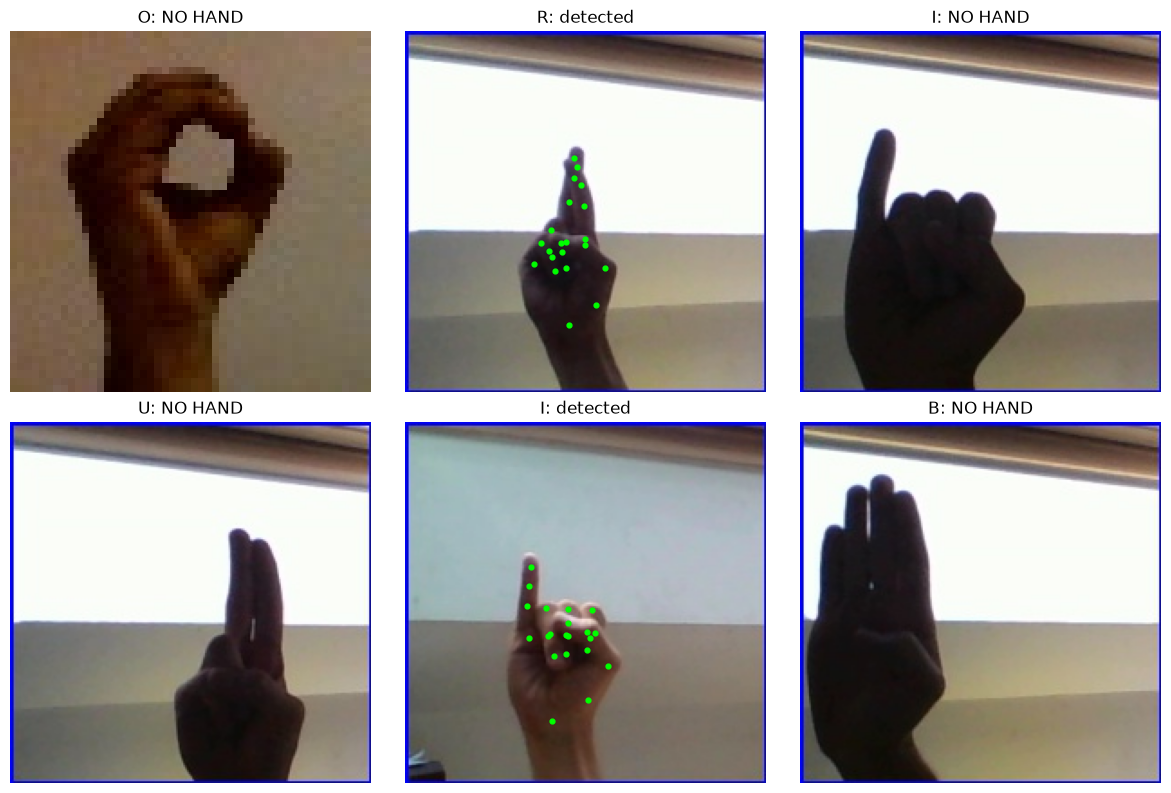

In [7]:
train_paths, train_labels = find_images(TRAIN_ROOT)

sample_indices = np.random.default_rng(42).choice(
    len(train_paths),
    size=min(6, len(train_paths)),
    replace=False,
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:
    ax.axis("off")

with create_landmarker() as landmarker:
    for ax, index in zip(axes.flat, sample_indices):
        rgb = read_rgb(train_paths[index])
        _, landmarks = get_features(rgb, landmarker)

        ax.imshow(rgb)

        if landmarks:
            height, width = rgb.shape[:2]
            ax.scatter(
                [point.x * width for point in landmarks],
                [point.y * height for point in landmarks],
                s=12,
                c="lime",
            )
            status = "detected"
        else:
            status = "NO HAND"

        ax.set_title(f"{LETTERS[train_labels[index]]}: {status}")

plt.tight_layout()
plt.show()

In [8]:
train_indices, val_indices = train_test_split(
    np.arange(len(train_paths)),
    test_size=0.2,
    random_state=42,
    stratify=train_labels,
)

# Extract once, then select the corresponding rows.
features_all, training_failures = extract_features(train_paths)

X_train = features_all[train_indices]
y_train = train_labels[train_indices]

X_val = features_all[val_indices]
y_val = train_labels[val_indices]

train_ok = np.isfinite(X_train).all(axis=1)

print(f"Training hand detection: {train_ok.mean():.1%}")
print("First loading/detection failures:", training_failures[:3])

# All 24 classes must have usable training examples.
missing = set(range(24)) - set(y_train[train_ok])

if missing:
    raise ValueError(
        f"No usable training images for: {[LETTERS[i] for i in sorted(missing)]}"
    )

W0000 00:00:1792492042.621549  185894 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792492042.623597  185894 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/138199 [00:00<?, ?it/s]

Training hand detection: 80.1%
First loading/detection failures: [('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg', 'No usable hand landmarks'), ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002_copy.jpg', 'No usable hand landmarks'), ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1004.jpg', 'No usable hand landmarks')]


In [11]:
import pandas as pd

In [14]:
features = features_all
paths = train_paths
labels = train_labels

features_df = pd.DataFrame(features)

dataset_labels = []
users = []
for p in paths:
    splits = p.name.split('__')
    dataset_labels += [splits[0]]
    if len(splits)>2:
        users += [splits[1]]
    else:
        users += [""]

# Add label
features_df["letter_index"] = labels

# Add Dataset label
features_df["dataset"] = dataset_labels

# Add User/Person
features_df["user"] = users

# Add image path
features_df["image_path"] = [str(p) for p in paths]

features_df.to_csv("handlandmarks_d01megadataset.csv")

In [9]:
classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=24,
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=4,
)

classifier.fit(
    X_train[train_ok],
    y_train[train_ok],
)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

In [10]:
def evaluate_pipeline(classifier, features, labels, name):
    usable = np.isfinite(features).all(axis=1)

    # -1 means no prediction; always incorrect for our letter labels.
    predictions = np.full(len(labels), -1, dtype=np.int64)

    if usable.any():
        predictions[usable] = classifier.predict(
            features[usable]
        ).astype(np.int64)

    print(f"\n{name}")
    print(f"Images: {len(labels)}")
    print(f"Usable hand detection: {usable.mean():.2%}")
    print(f"Overall accuracy: {(predictions == labels).mean():.2%}")

    if usable.any():
        accuracy = accuracy_score(
            labels[usable], predictions[usable]
        )
        print(f"Accuracy on detected hands: {accuracy:.2%}")

    return predictions


val_predictions = evaluate_pipeline(
    classifier, X_val, y_val, "Validation"
)


Validation
Images: 27640
Usable hand detection: 79.85%
Overall accuracy: 79.49%
Accuracy on detected hands: 99.55%


In [ ]:
external_paths, y_external = find_images(EXTERNAL_ROOT)

X_external, external_failures = extract_features(external_paths)

external_predictions = evaluate_pipeline(
    classifier,
    X_external,
    y_external,
    "ASLYset external evaluation",
)

In [ ]:
print(classification_report(
    y_external,
    external_predictions,
    labels=np.arange(24),
    target_names=list(LETTERS),
    digits=3,
    zero_division=0,
))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Your existing 24-letter mapping.
LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"

# Convert failure value -1 to index 24 for display.
predictions = np.where(
    external_predictions == -1,
    24,
    external_predictions,
)

display_labels = list(LETTERS) + ["No hand"]

matrix = confusion_matrix(
    y_external,
    predictions,
    labels=np.arange(25),
)

fig, ax = plt.subplots(figsize=(16, 13))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=display_labels,
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False,
)

ax.set_title("MediaPipe + XGBoost — ASLYset External Test")
plt.tight_layout()
plt.show()